In [1]:
# imports

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
import seaborn as sns
import sqlite3

from itertools import product
from sklearn.linear_model import LinearRegression

# set up rng seed for reproducibility
rng = np.random.default_rng(seed=9481)


# Clean genome metatdata
- Impute missing completeness data
- Simplify dataframe and save as `data/genome-metadata.csv`

In [2]:
# read in genome metadata

metadata_path = Path('../data/inputs/pro-genomes.csv')
genome_df = pd.read_csv(metadata_path)

genome_df

,Genome_Name,Genus,Clade,Sequencing_Status,Study_Name,Sample_Name,IMG_Genome_ID,Analysis_Project_Type,NCBI_Taxon_ID,NCBI_Biosample_Accession,NCBI_GenBank_ID,Depth,Latitude,Longitude,Genome_Size,Gene_Count,Completeness,Contamination,Path,GenomeAlias
0,AC-669-I9,Prochlorococcus,AMZ-I,Permanent Draft,Microbial Oceanography of picocyanobacteria in...,Prochlorococcus sp. SCGC AC-669 I9 (contaminat...,2626541507,Single Cell Analysis (screened),159733,NaN,NaN,53.0,-20.351667,-70.80,1964467,2686,65.91,7.22,data/0-inputs/genomes/2626541507,ProchlorococcusAC669I9
1,AC-669-J22,Prochlorococcus,AMZ-I,Permanent Draft,Microbial Oceanography of picocyanobacteria in...,Prochlorococcus sp. SCGC AC-669 J22 (contamina...,2626541512,Single Cell Analysis (screened),159733,NaN,NaN,53.0,-20.351667,-70.80,1826776,2523,65.28,6.84,data/0-inputs/genomes/2626541512,ProchlorococcusAC669J22
2,AC-669-O11,Prochlorococcus,AMZ-I,Permanent Draft,Microbial Oceanography of picocyanobacteria in...,Prochlorococcus sp. SCGC AC-669 O11 (contamina...,2626541532,Single Cell Analysis (screened),159733,NaN,NaN,53.0,-20.351667,-70.80,1671148,2032,63.19,1.14,data/0-inputs/genomes/2626541532,ProchlorococcusAC669O11
3,AC-669-K21,Prochlorococcus,AMZ-I,Permanent Draft,Microbial Oceanography of picocyanobacteria in...,Prochlorococcus sp. SCGC AC-669 K21 (contamina...,2626541518,Single Cell Analysis (screened),159733,NaN,NaN,53.0,-20.351667,-70.80,1597402,1953,57.31,3.30,data/0-inputs/genomes/2626541518,ProchlorococcusAC669K21
4,AC-669-K20,Prochlorococcus,AMZ-I,Permanent Draft,Microbial Oceanography of picocyanobacteria in...,Prochlorococcus sp. SCGC AC-669 K20 (contamina...,2626541517,Single Cell Analysis (screened),159733,NaN,NaN,53.0,-20.351667,-70.80,1706781,2490,55.87,3.13,data/0-inputs/genomes/2626541517,ProchlorococcusAC669K20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1101,MIT1223,Prochlorococcus,LLVIII,Finished,ProPortal-Culture-Genomes,Prochlorococcus sp. MIT1223,2681813568,Genome Analysis (Isolate),1220,NaN,NaN,175.0,22.750000,-158.00,1795922,1991,100.00,0.05,data/0-inputs/genomes/2681813568,ProchlorococcusMIT1223
1102,AG-402-N21,Prochlorococcus,LLVIII,Draft,HOT-BATS-SingleCells,Prochlorococcus sp. AG-402-N21 (Screened),2667527276,Single Cell Analysis (screened),2162096,SAMN08886333,QCIW00000000,NaN,22.750000,-158.00,1364872,1545,76.19,0.10,data/0-inputs/genomes/2667527276,ProchlorococcusAG402N21
1103,AG-409-P19,Prochlorococcus,LLVIII,Draft,bioGEOTRACES-SingleCells,Prochlorococcus sp. AG-409-P19,2716884399,Single Cell Analysis (unscreened),2162277,SAMN08886377,QCKO00000000,NaN,9.550000,-50.47,1164213,1300,67.11,0.32,data/0-inputs/genomes/2716884399,ProchlorococcusAG409P19
1104,AG-409-D09,Prochlorococcus,LLVIII,Draft,bioGEOTRACES-SingleCells,Prochlorococcus sp. AG-409-D09,2716884266,Single Cell Analysis (unscreened),2162204,SAMN08886353,QCJQ00000000,NaN,9.550000,-50.47,1218575,1438,64.91,0.00,data/0-inputs/genomes/2716884266,ProchlorococcusAG409D09


,Genome_Name,Genus,Clade,Sequencing_Status,Study_Name,Sample_Name,IMG_Genome_ID,Analysis_Project_Type,NCBI_Taxon_ID,NCBI_Biosample_Accession,...,Depth,Latitude,Longitude,Genome_Size,Gene_Count,Completeness,Contamination,Path,GenomeAlias,Imputed_Completeness
123,AG-321-O21,Prochlorococcus,HLI,Draft,BiGRAPA-SouthPacific-SingleCells,Uncultured Prochlorococcus sp. AG-321-O21,2716884648,Single Cell Analysis (unscreened),1218,SAMN08886018,...,NaN,-23.46,-88.77,99003,123,10.148355,NaN,data/0-inputs/genomes/2716884648,ProchlorococcusAG321O21,True
124,AG-343-G04,Prochlorococcus,HLI,Permanent Draft,Charting the complexity of the marine microbio...,Synechococcaceae cyanobacterium AG-343-G04,8135953660,Single Cell Analysis (unscreened),1665021,SAMEA6078190,...,NaN,NaN,NaN,91721,123,9.890947,NaN,data/0-inputs/genomes/8135953660,ProchlorococcusAG343G04,True
271,AG-422-G21,Prochlorococcus,HLII,Permanent Draft,Charting the complexity of the marine microbio...,Prochlorococcus sp. AG-422-G21,8026898962,Single Cell Analysis (unscreened),159733,SAMEA6076281,...,NaN,NaN,NaN,1334801,1674,73.403590,NaN,data/0-inputs/genomes/8026898962,ProchlorococcusAG422G21,True
272,AG-430-N10,Prochlorococcus,HLII,Permanent Draft,Charting the complexity of the marine microbio...,Synechococcaceae cyanobacterium AG-430-N10,8135953788,Single Cell Analysis (unscreened),1665021,SAMEA6079953,...,NaN,NaN,NaN,92575,130,10.009465,NaN,data/0-inputs/genomes/8135953788,ProchlorococcusAG430N10,True
843,AG-333-B07,Prochlorococcus,LLI,Permanent Draft,Charting the complexity of the marine microbio...,Prochlorococcus sp. AG-333-B07,8135953923,Single Cell Analysis (unscreened),159733,SAMEA6077524,...,NaN,NaN,NaN,91609,125,9.912225,NaN,data/0-inputs/genomes/8135953923,ProchlorococcusAG333B07,True
966,MIT1304,Prochlorococcus,LLII-LLIII,Permanent Draft,ProPortal-Culture-Genomes,Prochlorococcus sp. MIT1304,2681813571,Genome Analysis (Isolate),1220,NaN,...,150.0,22.75,-158.00,1762159,1952,92.018079,NaN,data/0-inputs/genomes/2681813571,ProchlorococcusMIT1304,True
1006,MIT1205,Prochlorococcus,LLIV,Permanent Draft,ProPortal-Culture-Genomes,Prochlorococcus sp. MIT1205,2681813566,Genome Analysis (Isolate),1220,NaN,...,175.0,22.75,-158.00,2527266,2674,100.000000,NaN,data/0-inputs/genomes/2681813566,ProchlorococcusMIT1205,True


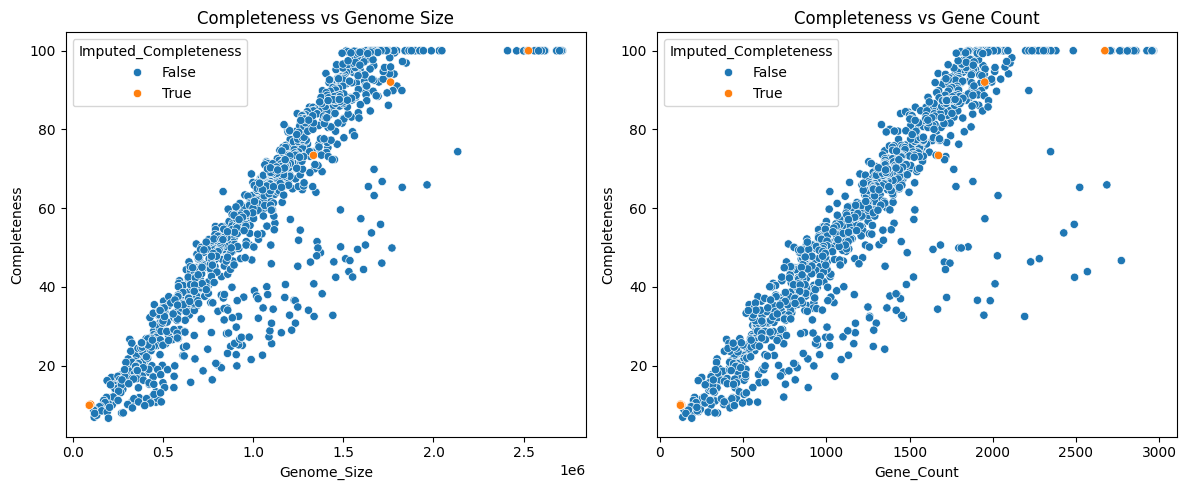

In [3]:
# impute missing completeness values with linear regression based on genome size and gene count

complete_df = genome_df.dropna(subset=['Completeness']) 
X = complete_df[['Genome_Size', 'Gene_Count']]
y = complete_df['Completeness']
model = LinearRegression()
model.fit(X, y)
missing_df = genome_df[genome_df['Completeness'].isna()]
X_missing = missing_df[['Genome_Size', 'Gene_Count']]
imputed_completeness = model.predict(X_missing)

# clip imputed values to valid range [0, 100]
imputed_completeness = np.clip(imputed_completeness, 0, 100)

# add imputed values back to genome_df, keeping track of which values were imputed
genome_df['Imputed_Completeness'] = genome_df['Completeness'].isna()
genome_df.loc[genome_df['Completeness'].isna(), 'Completeness'] = imputed_completeness
display(genome_df.loc[genome_df['Imputed_Completeness']])

# plot completeness vs genome size and vs gene count with imputed values highlighted
fig, axes = plt.subplots(1, 2, figsize=(12, 5)) 
sns.scatterplot(
    data=genome_df.sort_values(by='Imputed_Completeness'),
    x='Genome_Size',
    y='Completeness',
    hue='Imputed_Completeness',
    ax=axes[0]
)
axes[0].set_title('Completeness vs Genome Size')
sns.scatterplot(
    data=genome_df.sort_values(by='Imputed_Completeness'),
    x='Gene_Count',
    y='Completeness',
    hue='Imputed_Completeness',
    ax=axes[1]
)
axes[1].set_title('Completeness vs Gene Count')
plt.tight_layout()
plt.show()

In [4]:
# save and simplify metadata for downstream use

metadata_output_path = Path('../data/pro_pangenome_metadata.csv')

# simplify metadata
metadata_df = genome_df[[
    'GenomeAlias', 'Clade', 'Completeness', 
    'Sequencing_Status', 'Imputed_Completeness']]
metadata_df = metadata_df.rename(columns={
    'GenomeAlias': 'genome',
    'Clade': 'clade',
    'Completeness': 'completeness',
    'Sequencing_Status': 'sequencing_status',
    'Imputed_Completeness': 'imputed_completeness'
})
metadata_df['complete'] = metadata_df['sequencing_status'] == 'Finished'

# save metadata to CSV
metadata_df.to_csv(metadata_output_path, index=False)

metadata_df

,genome,clade,completeness,sequencing_status,imputed_completeness,complete
0,ProchlorococcusAC669I9,AMZ-I,65.91,Permanent Draft,False,False
1,ProchlorococcusAC669J22,AMZ-I,65.28,Permanent Draft,False,False
2,ProchlorococcusAC669O11,AMZ-I,63.19,Permanent Draft,False,False
3,ProchlorococcusAC669K21,AMZ-I,57.31,Permanent Draft,False,False
4,ProchlorococcusAC669K20,AMZ-I,55.87,Permanent Draft,False,False
...,...,...,...,...,...,...
1101,ProchlorococcusMIT1223,LLVIII,100.00,Finished,False,True
1102,ProchlorococcusAG402N21,LLVIII,76.19,Draft,False,False
1103,ProchlorococcusAG409P19,LLVIII,67.11,Draft,False,False
1104,ProchlorococcusAG409D09,LLVIII,64.91,Draft,False,False


# Clean count data
- Build matrix of gene family count data
- Save incomplete and complete datasets separately

In [5]:
# generate gene family count matrix from anvi'o pangenome database

db_path = Path('../data/inputs/propan-PAN.db')

query = '''
SELECT
  gene_caller_id, 
  gene_cluster_id,
  genome_name,
  COUNT(*) AS occurrences
FROM gene_clusters
GROUP BY gene_caller_id, gene_cluster_id, genome_name
'''.strip()

with sqlite3.connect(db_path) as conn:
    long_df = pd.read_sql_query(query, conn)

gc_count_df = long_df.pivot_table(
    index='gene_cluster_id',
    columns='genome_name',
    values='occurrences',
    aggfunc='sum',
    fill_value=0,
)

gc_count_df

genome_name,ProchlorococcusAC669E6,ProchlorococcusAC669I11,ProchlorococcusAC669I15,ProchlorococcusAC669I23,ProchlorococcusAC669I4,ProchlorococcusAC669I9,ProchlorococcusAC669J11,ProchlorococcusAC669J17,ProchlorococcusAC669J2,ProchlorococcusAC669J20,...,ProchlorococcusW10,ProchlorococcusW11,ProchlorococcusW12,ProchlorococcusW2,ProchlorococcusW3,ProchlorococcusW4,ProchlorococcusW6,ProchlorococcusW7,ProchlorococcusW8,ProchlorococcusW9
gene_cluster_id,,,,,,,,,,,,,,,,,,,,,
GC_00000001,0,0,0,0,0,0,0,3,0,0,...,4,2,11,11,2,13,0,4,0,1
GC_00000002,1,1,2,4,5,4,1,2,1,1,...,1,2,0,3,0,2,2,2,2,1
GC_00000003,4,1,2,3,1,5,2,2,3,1,...,3,3,0,3,0,3,0,1,1,6
GC_00000004,2,1,2,2,3,2,3,1,17,0,...,1,0,1,1,0,0,1,1,0,1
GC_00000005,3,1,5,9,6,6,4,6,21,22,...,3,3,0,1,0,0,0,3,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GC_00052854,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
GC_00052855,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
GC_00052856,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [6]:
# build presence-absence matrix from count matrix

gc_pa_df = gc_count_df.copy()
gc_pa_df[gc_pa_df > 0] = 1
gc_pa_df

genome_name,ProchlorococcusAC669E6,ProchlorococcusAC669I11,ProchlorococcusAC669I15,ProchlorococcusAC669I23,ProchlorococcusAC669I4,ProchlorococcusAC669I9,ProchlorococcusAC669J11,ProchlorococcusAC669J17,ProchlorococcusAC669J2,ProchlorococcusAC669J20,...,ProchlorococcusW10,ProchlorococcusW11,ProchlorococcusW12,ProchlorococcusW2,ProchlorococcusW3,ProchlorococcusW4,ProchlorococcusW6,ProchlorococcusW7,ProchlorococcusW8,ProchlorococcusW9
gene_cluster_id,,,,,,,,,,,,,,,,,,,,,
GC_00000001,0,0,0,0,0,0,0,1,0,0,...,1,1,1,1,1,1,0,1,0,1
GC_00000002,1,1,1,1,1,1,1,1,1,1,...,1,1,0,1,0,1,1,1,1,1
GC_00000003,1,1,1,1,1,1,1,1,1,1,...,1,1,0,1,0,1,0,1,1,1
GC_00000004,1,1,1,1,1,1,1,1,1,0,...,1,0,1,1,0,0,1,1,0,1
GC_00000005,1,1,1,1,1,1,1,1,1,1,...,1,1,0,1,0,0,0,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GC_00052854,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
GC_00052855,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
GC_00052856,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [7]:
# save full pangenome count and presence-absence matrices for downstream use

count_output_path = Path('../data/pro_pangenome_count_data.csv')
pa_output_path = Path('../data/pro_pangenome_presence_absence_data.csv')

gc_count_df.to_csv(count_output_path, index=True)
gc_pa_df.to_csv(pa_output_path, index=True)

## Subsets
Separate out subsets of data for downstream use
- complete vs incomplete genomes
- complete vs incomplete genomes with proportional clade representation

In [8]:
# separate out complete and incomplete genome subsets

complete_genomes = metadata_df[metadata_df['complete']]['genome']
incomplete_genomes = metadata_df[~metadata_df['complete']]['genome']
print(f'Complete genomes: {len(complete_genomes)}')
print(f'Incomplete genomes: {len(incomplete_genomes)}')

# make sure output directory exists
subsets_dir = Path('../data/subsets')
subsets_dir.mkdir(parents=True, exist_ok=True)

# separate count and presence-absence matrices for complete and incomplete genomes
gc_count_complete_df = gc_count_df[complete_genomes]
gc_count_incomplete_df = gc_count_df[incomplete_genomes]
gc_pa_complete_df = gc_pa_df[complete_genomes]
gc_pa_incomplete_df = gc_pa_df[incomplete_genomes]

# save subsets to CSV
gc_count_complete_df.to_csv(subsets_dir / 'pro_count_data_complete.csv', index=True)
gc_count_incomplete_df.to_csv(subsets_dir / 'pro_count_data_incomplete.csv', index=True)
gc_pa_complete_df.to_csv(subsets_dir / 'pro_presence_absence_data_complete.csv', index=True)
gc_pa_incomplete_df.to_csv(subsets_dir / 'pro_presence_absence_data_incomplete.csv', index=True)

gc_count_complete_df

Complete genomes: 65
Incomplete genomes: 1041


genome_name,ProchlorococcusDV,ProchlorococcusMIT9515,ProchlorococcusMED1,ProchlorococcusMED4,ProchlorococcusMIT9123,ProchlorococcusMIT0604,ProchlorococcusMIT9302,ProchlorococcusMIT9116,ProchlorococcusMIT9314,ProchlorococcusMIT9201,...,ProchlorococcusMIT1201,ProchlorococcusMIT1306,ProchlorococcusMIT1342,ProchlorococcusMIT1303,ProchlorococcusMIT1323,ProchlorococcusMIT1320,ProchlorococcusMIT1307,ProchlorococcusMIT1341,ProchlorococcusMIT1300,ProchlorococcusMIT1223
gene_cluster_id,,,,,,,,,,,,,,,,,,,,,
GC_00000001,13,12,13,13,7,5,12,7,10,10,...,4,4,4,3,4,4,5,4,7,4
GC_00000002,3,3,3,3,3,3,3,3,3,3,...,3,3,4,3,3,3,3,3,3,3
GC_00000003,3,3,3,3,3,3,3,3,3,3,...,3,3,3,3,3,3,3,3,3,3
GC_00000004,1,2,1,1,2,2,2,2,2,2,...,2,2,2,2,2,2,8,7,6,7
GC_00000005,2,2,2,2,2,2,2,2,2,2,...,2,2,2,2,2,2,2,2,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GC_00052854,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
GC_00052855,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
GC_00052856,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [9]:
# subsample complete and incomplete genomes to create class-balanced datasets for testing
# (i.e. complete and incomplete genomes will have the same clade composition)

# count number of complete and incomplete genomes per clade in full set of Pro genomes
clade_count_df = metadata_df.groupby('clade').complete.value_counts().unstack(fill_value=0)
clade_count_df = clade_count_df.rename(
    columns={True: 'n_complete_total', False: 'n_incomplete_total'})[
    ['n_complete_total', 'n_incomplete_total']]
clade_count_df.columns.name = None
clade_count_df.index.name = None

# calculate number of genomes to downsample from each clade for complete and incomplete subsets
factor = 6
clade_count_df['n_complete_subset'] = clade_count_df['n_complete_total'].clip(upper=clade_count_df['n_incomplete_total'])
clade_count_df['n_incomplete_subset'] = clade_count_df['n_incomplete_total'].clip(upper=clade_count_df['n_complete_total'] * factor)
clade_count_df['n_complete_subset'] = clade_count_df['n_complete_subset'].clip(upper=clade_count_df['n_incomplete_subset'] // factor)
clade_count_df['n_incomplete_subset'] = clade_count_df['n_incomplete_total'].clip(upper=clade_count_df['n_complete_subset'] * factor)
clade_count_df['frac_subset'] = clade_count_df['n_complete_subset'] / clade_count_df['n_complete_subset'].sum()

# randomly select genomes for complete and incomplete subsets based on calculated numbers
complete_subset_genomes = []
incomplete_subset_genomes = []
for clade, row in clade_count_df.iterrows():
    complete_genomes_clade = metadata_df[
        (metadata_df['clade'] == clade) & (metadata_df['complete'])]['genome']
    incomplete_genomes_clade = metadata_df[
        (metadata_df['clade'] == clade) & (~metadata_df['complete'])]['genome']
    complete_subset_genomes.extend(
        rng.choice(
            complete_genomes_clade, size=row['n_complete_subset'].astype(int), replace=False))
    incomplete_subset_genomes.extend(
        rng.choice(
            incomplete_genomes_clade, size=row['n_incomplete_subset'].astype(int), replace=False))

print(f'Total genomes sampled for complete subset: {clade_count_df["n_complete_subset"].sum()}')
print(f'Total genomes sampled for incomplete subset: {clade_count_df["n_incomplete_subset"].sum()}')
print(f'Overall total genomes sampled: {clade_count_df[["n_complete_subset", "n_incomplete_subset"]].sum().sum()}')
print(f'Overall total clades sampled: {clade_count_df[["n_complete_subset", "n_incomplete_subset"]].gt(0).any(axis=1).sum()}')

clade_count_df

Total genomes sampled for complete subset: 44
Total genomes sampled for incomplete subset: 264
Overall total genomes sampled: 308
Overall total clades sampled: 6


,n_complete_total,n_incomplete_total,n_complete_subset,n_incomplete_subset,frac_subset
AMZ-I,0,48,0,0,0.000000
AMZ-II,0,32,0,0,0.000000
AMZ-III,0,43,0,0,0.000000
HLI,4,144,4,24,0.090909
HLII,17,502,17,102,0.386364
HLII-HLVI,0,2,0,0,0.000000
HLIII,0,9,0,0,0.000000
HLIV,0,30,0,0,0.000000
HLVI,0,12,0,0,0.000000
LLI,13,110,13,78,0.295455


In [10]:
# pull out and save the count and presence-absence matrices for the complete and incomplete subsets

gc_count_complete_clade_balanced_df = gc_count_df[complete_subset_genomes]
gc_count_incomplete_clade_balanced_df = gc_count_df[incomplete_subset_genomes]
gc_pa_complete_clade_balanced_df = gc_pa_df[complete_subset_genomes]
gc_pa_incomplete_clade_balanced_df = gc_pa_df[incomplete_subset_genomes]

gc_count_complete_clade_balanced_df.to_csv(subsets_dir / 'pro_count_data_complete_clade_balanced.csv', index=True)
gc_count_incomplete_clade_balanced_df.to_csv(subsets_dir / 'pro_count_data_incomplete_clade_balanced.csv', index=True)
gc_pa_complete_clade_balanced_df.to_csv(subsets_dir / 'pro_presence_absence_data_complete_clade_balanced.csv', index=True)
gc_pa_incomplete_clade_balanced_df.to_csv(subsets_dir / 'pro_presence_absence_data_incomplete_clade_balanced.csv', index=True)

# show saved files in directory
for f in subsets_dir.iterdir():
    print(f'✅ {f.name}')

✅ pro_presence_absence_data_incomplete.csv
✅ pro_presence_absence_data_complete_clade_balanced.csv
✅ pro_presence_absence_data_complete.csv
✅ pro_count_data_incomplete_clade_balanced.csv
✅ pro_count_data_incomplete.csv
✅ pro_presence_absence_data_incomplete_clade_balanced.csv
✅ pro_count_data_complete.csv
✅ pro_count_data_complete_clade_balanced.csv


# Generate simulated datasets
1. Dataset with assumptions that match the model (i.e. the case the model is well-specified).
2. Dataset with biased gene detection (some genes are more likely to be detected than others).
3. Dataset generated from simulated count data in which there are multiple copies of some genes.

Total core genes (prevalence=1): 805
Total genes without any presence: 0
Median genes per genome: 2997.0


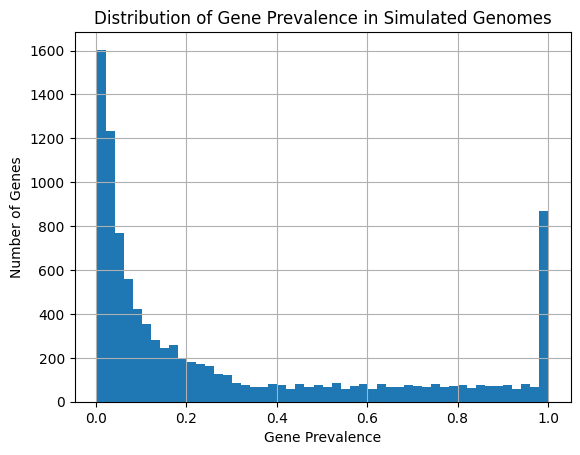

In [11]:
# Build simulated presence-absence matrices representing complete genomes.
# This is the underlying truth that we will later mask to create the simulated datasets
# representing incompletely sequenced genomes with missing data.

# simulated data parameters
n_genomes = 1000
n_genes = 10000
n_core = 800
n_moderate = 2500 # number of moderately prevalent accessory genes
p_ranges = [1, 0.3, 0.01] # prevalence ranges for core, moderately prevalent accessory, and rare accessory genes

# build simulated presence-absence matrix 
simulated_genomes = [f'sim_genome_{i}' for i in range(n_genomes)]
simulated_genes = [f'sim_gene_{i}' for i in range(n_genes)]
sim_complete_df = pd.DataFrame(index=simulated_genes, columns=simulated_genomes)

# build p_vector (generating probabilites for gene prevalences)
p_vector = np.concatenate([
    np.ones_like(np.arange(n_core)),  # core genes with prevalence 1
    np.linspace(p_ranges[0], p_ranges[1], n_moderate),  # moderately prevalent accessory genes
    np.logspace(np.log10(p_ranges[1]), np.log10(p_ranges[2]), n_genes - n_core - n_moderate),  # rare accessory genes
])

# generate presence-absence data for simulated genomes
for genome in simulated_genomes:
    sim_complete_df[genome] = rng.random(n_genes) < p_vector

# convert boolean presence-absence matrix to integer (0/1) for downstream use
sim_complete_df = sim_complete_df.astype(int)

# verify that the simulated presence/absence data matches the intended parameters
print(f'Total core genes (prevalence=1): {sim_complete_df.eq(1).all(axis=1).sum()}')
print(f'Total genes without any presence: {sim_complete_df.eq(0).all(axis=1).sum()}')
print(f'Median genes per genome: {sim_complete_df.sum(axis=0).median()}')

# show plot of gene prevalence distribution in simulated data
sim_complete_df.mean(axis=1).hist(bins=50)
plt.xlabel('Gene Prevalence')
plt.ylabel('Number of Genes')
plt.title('Distribution of Gene Prevalence in Simulated Genomes')
plt.show()


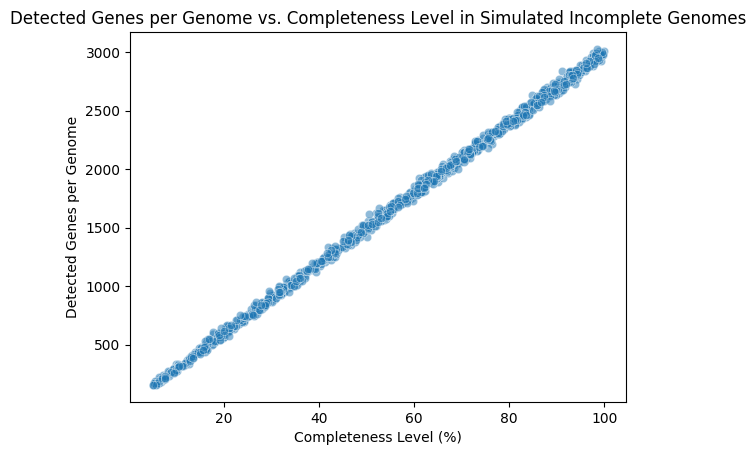

In [12]:
# Simulated Dataset 1:
# Simulate incomplete genomes by applying random masking to the complete simulated 
# presence-absence data

# randomly set completeness level of simulated genomes between 5% and 100%
completeness_levels = rng.uniform(0.05, 1.0, size=n_genomes)

# build incomplete presence-absence matrix by masking genes in complete matrix 
# according to completeness levels
sim_incomplete_df = sim_complete_df.copy()
for gene in simulated_genes:
    observed_genes = rng.random(n_genomes) < completeness_levels
    sim_incomplete_df.loc[gene] = sim_complete_df.loc[gene] * observed_genes

# # alternative approach that fixes number of genes observed per genome based on 
# # completeness level, but introduces subtle correlations to the pi estimators for each 
# # genome, based on the dependency of observing gene 1 given you've observed gene 2, etc.
# for genome, completeness in zip(simulated_genomes, completeness_levels):
#     # retrieve locations of genes present in the complete genome
#     present_genes = sim_complete_df[genome].astype(bool)
#     # determine how many of the present genes to mask based on the completeness level
#     n_present = present_genes.sum()
#     n_to_mask = round(n_present * (1 - completeness))
#     if n_to_mask > 0:
#         # randomly select genes to mask from the present genes
#         genes_to_mask = rng.choice(
#             sim_complete_df.index[present_genes], size=n_to_mask, replace=False)
#         sim_incomplete_df.loc[genes_to_mask, genome] = 0

# look at detected genes per genome in simulated incomplete data
sns.scatterplot(x=completeness_levels * 100, y=sim_incomplete_df.sum(axis=0), alpha=0.5)
plt.xlabel('Completeness Level (%)')
plt.ylabel('Detected Genes per Genome')
plt.title('Detected Genes per Genome vs. Completeness Level in Simulated Incomplete Genomes')
plt.show()
    

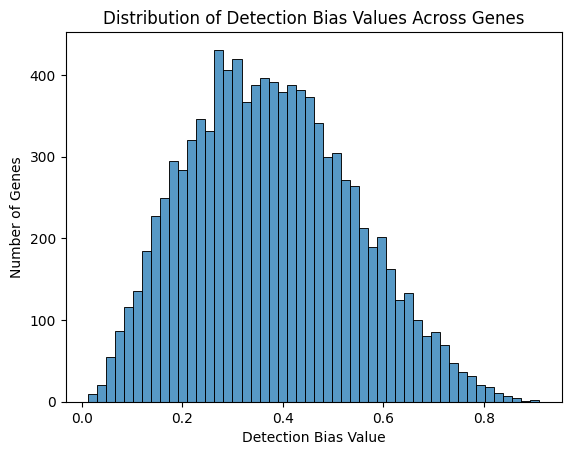

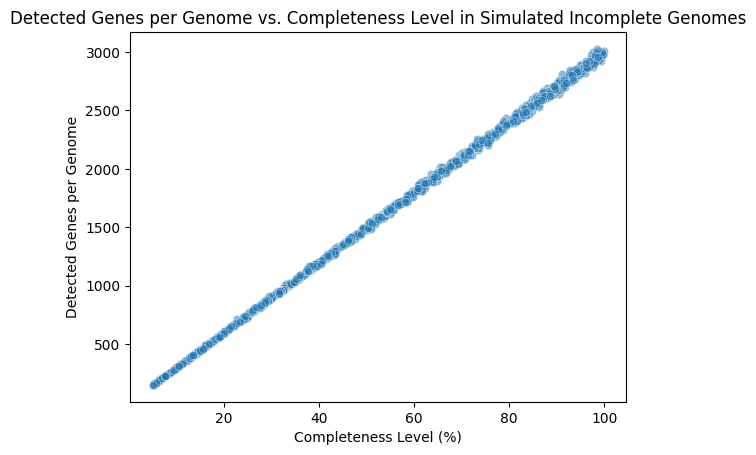

In [13]:
# Simulated Dataset 2: 
# Simulate incomplete genomes in which the some genes are systematically more likely 
# to be missing than others.

# randomly set sampling bias for each gene, where higher values indicate 
# greater likelihood of being detected (i.e. less likely to be missing) in incomplete genomes
detection_bias = rng.beta(a=3, b=5, size=n_genes)  # bias towards missing certain genes

# plot distribution of detection bias values across genes
sns.histplot(detection_bias, bins=50)
plt.xlabel('Detection Bias Value')
plt.ylabel('Number of Genes')
plt.title('Distribution of Detection Bias Values Across Genes')
plt.show()

# build biased incomplete presence-absence matrix by masking genes in complete matrix 
# according to completeness levels and detection bias
sim_incomplete_biased_df = sim_complete_df.copy()
for genome, completeness in zip(simulated_genomes, completeness_levels):
    # retrieve locations of genes present in the complete genome
    present_genes = sim_complete_df[genome].astype(bool)
    # determine how many of the present genes to mask based on the completeness level
    n_present = present_genes.sum()
    n_detected = round(n_present * completeness)
    if n_detected < n_present:
        # randomly select genes that will be detected (i.e. not missing), using calculated detection bias
        genes_detected = rng.choice(
            sim_complete_df.index[present_genes], 
            size=n_detected, 
            replace=False, 
            p=detection_bias[present_genes]/detection_bias[present_genes].sum() # normalize biases
        )
        genes_to_mask = set(sim_complete_df.index[present_genes]) - set(genes_detected)
        sim_incomplete_biased_df.loc[list(genes_to_mask), genome] = 0

# look at detected genes per genome in simulated incomplete data
sns.scatterplot(x=completeness_levels * 100, y=sim_incomplete_biased_df.sum(axis=0), alpha=0.5)
plt.xlabel('Completeness Level (%)')
plt.ylabel('Detected Genes per Genome')
plt.title('Detected Genes per Genome vs. Completeness Level in Simulated Incomplete Genomes')
plt.show()

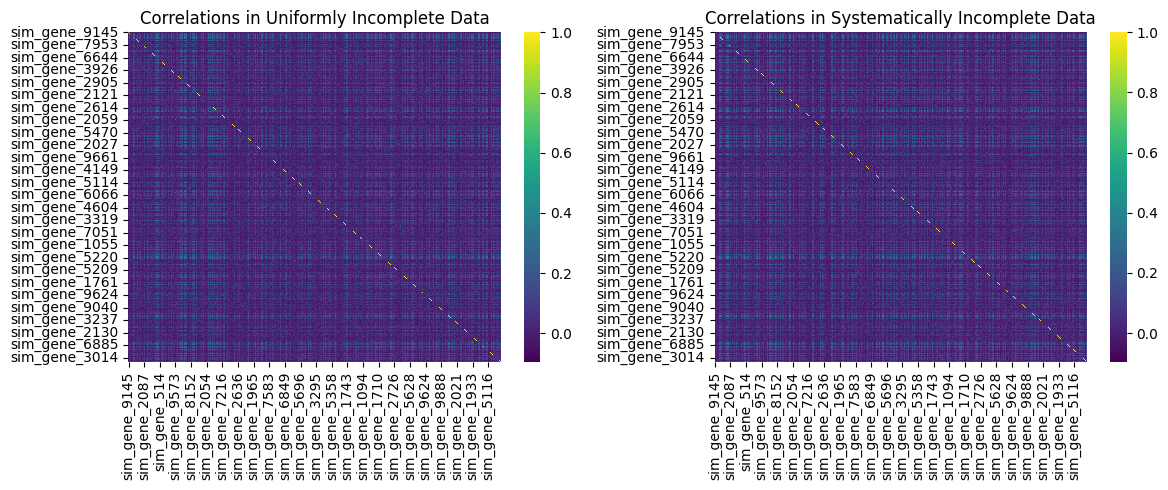

In [14]:
# compare heatmap of correlations between gene profiles in uniformly sampled incomplete data 
# and systematically sampled incomplete data

# select random subset of genes to look at correlations
subset = rng.choice(sim_incomplete_biased_df.index, size=1000, replace=False)

# compare uniformly and systematically incomplete data correlations
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(sim_incomplete_df.loc[subset].T.corr(), ax=axes[0], cmap='viridis')
axes[0].set_title('Correlations in Uniformly Incomplete Data')
sns.heatmap(sim_incomplete_biased_df.loc[subset].T.corr(), ax=axes[1], cmap='viridis')
axes[1].set_title('Correlations in Systematically Incomplete Data')
plt.tight_layout()
plt.show()


In [15]:
# save simulated datasets for downstream use

simulated_dir = Path('../data/simulated')
simulated_dir.mkdir(parents=True, exist_ok=True)

# save simulated presence/absence matrices
sim_complete_df.to_csv(simulated_dir / 'simulated_presence_absence_complete.csv', index=True)
sim_incomplete_df.to_csv(simulated_dir / 'simulated_presence_absence_incomplete.csv', index=True)
sim_incomplete_biased_df.to_csv(simulated_dir / 'simulated_presence_absence_incomplete_biased.csv', index=True)

# save completeness levels for simulated genomes
pd.DataFrame(
    completeness_levels, 
    index=simulated_genomes, 
    columns=['Completeness']).to_csv(simulated_dir / 'simulated_genome_completeness_levels.csv', index=True)

# save detection bias values for simulated genes
pd.DataFrame(
    detection_bias, 
    index=simulated_genes, 
    columns=['Detection_Bias']).to_csv(simulated_dir / 'simulated_gene_detection_bias_values.csv', index=True)

# show saved files in directory
for f in simulated_dir.iterdir():
    print(f'✅ {f.name}')

✅ simulated_presence_absence_incomplete.csv
✅ simulated_genome_completeness_levels.csv
✅ simulated_presence_absence_complete.csv
✅ simulated_presence_absence_incomplete_biased.csv
✅ simulated_gene_detection_bias_values.csv


### Simulated Count Data
Simulate gene counts to more faithfully represent multi-copy genes

11984 total detected genes across complete genomes
10968 single copy genes with mean count = 1 when present
1016 genes with mean count > 1 in genomes where present
869 total core genes in complete genomes
148 core genes with mean count > 1


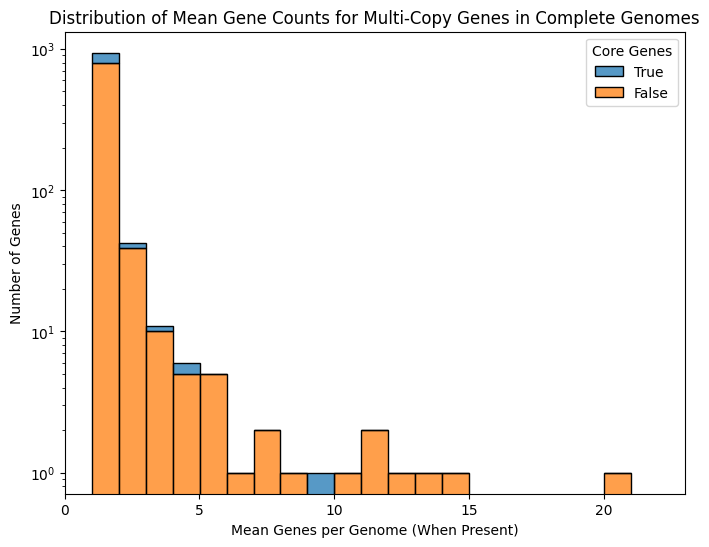

In [16]:
# look at distribution of multi-copy genes in real complete genome data

mean_gene_count = gc_count_complete_df[gc_count_complete_df > 0].mean(axis=1)
gene_count_vector = mean_gene_count[mean_gene_count > 1]
hue_vector = gc_count_complete_df[mean_gene_count > 1].gt(0).all(axis=1)
print(f'{mean_gene_count.gt(0).sum()} total detected genes across complete genomes')
print(f'{(mean_gene_count == 1).sum()} single copy genes with mean count = 1 when present')
print(f'{gene_count_vector.shape[0]} genes with mean count > 1 in genomes where present')
print(f'{gc_count_complete_df.gt(0).all(axis=1).sum()} total core genes in complete genomes')
print(f'{hue_vector.sum()} core genes with mean count > 1')

fig, ax = plt.subplots(figsize=(8, 6))
sns.histplot(
    x=gene_count_vector,
    hue=hue_vector,
    hue_order=[True, False],
    bins=20,
    legend=True,
    multiple='stack',
    ax=ax
)
ax.set_title('Distribution of Mean Gene Counts for Multi-Copy Genes in Complete Genomes')
ax.set_yscale('log')
ax.set_xlim(0, 23)
ax.set_xlabel('Mean Genes per Genome (When Present)')
ax.set_ylabel('Number of Genes')
ax.get_legend().set_title('Core Genes')


Total core genes (prevalence=1): 805
Total genes without any presence: 0
Median unique gene families per genome: 2997.0
Median genes per genome: 4140.5
10000 total represented genes in simulated genomes
8126 single copy genes with mean count = 1 when present
1874 genes with mean count > 1 in genomes where present
805 total core genes in simulated genomes
177 core genes with mean count > 1


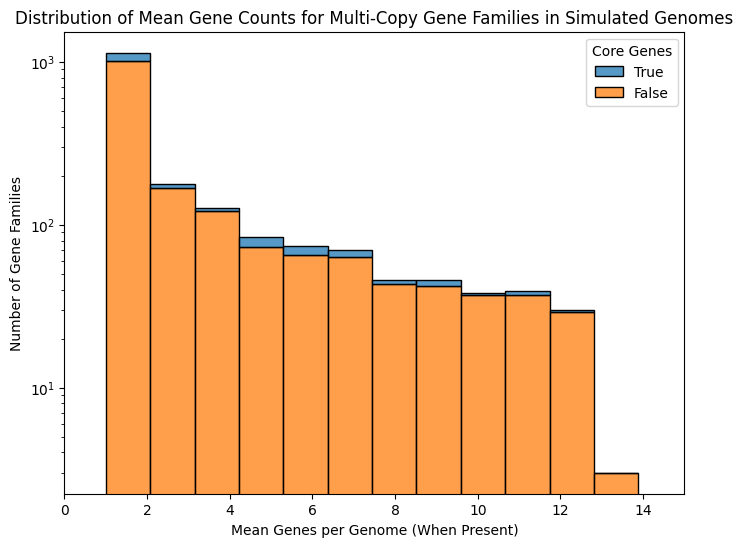

In [17]:
# generate count data from simulated presence-absence matrices 
# using Poisson distribution with lambda drawn from log space 
# to roughly reflect observed gene copy number distributions in complete genomes

# average copy number per gene family
lambda_vector = np.logspace(-10, 1.1, n_genes)
rng.shuffle(lambda_vector) # shuffle to avoid correlation with prevalence

# for each genome, draw gene counts from Poisson distribution, 
# with lambda equal to the average copy number for each gene family
count_factors = np.random.poisson(
    lam=lambda_vector[:, np.newaxis], 
    size=(n_genes, n_genomes))

# fill zeros counts with 1s to ensure that all present genes have at least 1 count
count_factors = np.where(count_factors == 0, 1, count_factors)

# multiply presence-absence matrix by count factors to get simulated count data
# so that absent genes have count of 0 and present genes have count >= 1 
# based on the Poisson distribution
sim_count_df = sim_complete_df.copy() * count_factors

# verify that the simulated count data matches the intended parameters
print(f'Total core genes (prevalence=1): {sim_count_df.ge(1).all(axis=1).sum()}')
print(f'Total genes without any presence: {sim_count_df.eq(0).all(axis=1).sum()}')
print(f'Median unique gene families per genome: {sim_count_df.ge(1).sum(axis=0).median()}')
print(f'Median genes per genome: {sim_count_df.sum(axis=0).median()}')

# look at distribution of multi-copy genes in simulated data
mean_gene_count = sim_count_df[sim_count_df > 0].mean(axis=1)
gene_count_vector = mean_gene_count[mean_gene_count > 1]
hue_vector = sim_count_df[mean_gene_count > 1].gt(0).all(axis=1)
print(f'{mean_gene_count.gt(0).sum()} total represented genes in simulated genomes')
print(f'{(mean_gene_count == 1).sum()} single copy genes with mean count = 1 when present')
print(f'{gene_count_vector.shape[0]} genes with mean count > 1 in genomes where present')
print(f'{sim_count_df.ge(1).all(axis=1).sum()} total core genes in simulated genomes')
print(f'{hue_vector.sum()} core genes with mean count > 1')

fig, ax = plt.subplots(figsize=(8, 6))
sns.histplot(
    x=gene_count_vector,
    hue=hue_vector,
    hue_order=[True, False],
    bins=12,
    legend=True,
    multiple='stack',
    ax=ax
)
ax.set_title('Distribution of Mean Gene Counts for Multi-Copy Gene Families in Simulated Genomes')
ax.set_yscale('log')
ax.set_xlim(0, 15)
ax.set_xlabel('Mean Genes per Genome (When Present)')
ax.set_ylabel('Number of Gene Families')
ax.get_legend().set_title('Core Genes')
plt.show()


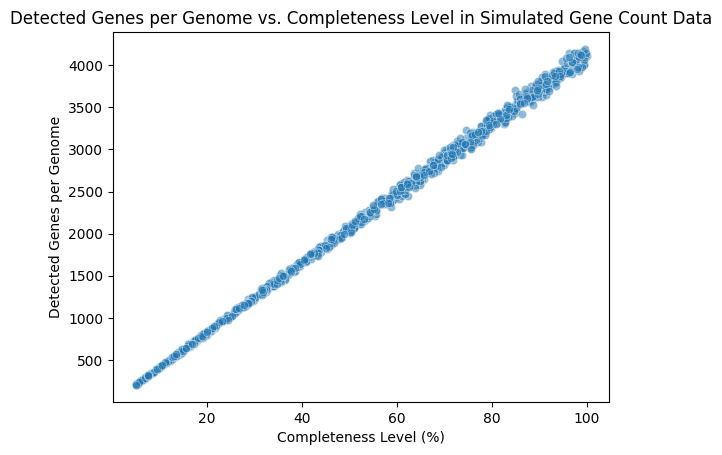

In [18]:
# Simulated Dataset 3: 
# Generate incomplete simulated count and presence/absence data based on 
# genome completeness levels.

sim_count_incomplete_df = pd.DataFrame(0, index=sim_count_df.index, columns=sim_count_df.columns)
for genome, completeness in zip(simulated_genomes, completeness_levels):
    # determine how many of the present genes to mask based on the completeness level
    n_present = sim_count_df[genome].sum()
    n_detected = round(n_present * completeness)
    if n_detected < n_present:
        # expand counts into list of genes (e.g. if gene A has count of 3, it will be represented as [A, A, A])
        genes = np.repeat(sim_count_df.index, sim_count_df[genome])
        # randomly draw genes that will be detected (i.e. not missing)
        genes_detected = rng.choice(
            genes, 
            size=n_detected, 
            replace=False, 
        )
        gene_counts = pd.Series(genes_detected).value_counts()
        sim_count_incomplete_df.loc[gene_counts.index, genome] = gene_counts.values

# look at detected genes per genome in simulated incomplete data
sns.scatterplot(x=completeness_levels * 100, y=sim_count_incomplete_df.sum(axis=0), alpha=0.5)
plt.xlabel('Completeness Level (%)')
plt.ylabel('Detected Genes per Genome')
plt.title('Detected Genes per Genome vs. Completeness Level in Simulated Gene Count Data')
plt.show()

In [19]:
# save simulated count data for downstream use

# simulated count data
sim_count_df.to_csv(simulated_dir / 'simulated_count_data_complete.csv', index=True)
sim_count_incomplete_df.to_csv(simulated_dir / 'simulated_count_data_incomplete.csv', index=True)

# save simulated mean gene count data
pd.DataFrame(
    mean_gene_count, 
    index=simulated_genes, 
    columns=['Mean_Gene_Count_When_Present']).to_csv(
        simulated_dir / 'simulated_mean_gene_counts_when_present.csv', index=True)

# for efficiency, also save a presence-absence version of the incomplete count data for downstream use
sim_pa_from_count_df = sim_count_incomplete_df.copy()
sim_pa_from_count_df[sim_pa_from_count_df > 0] = 1
sim_pa_from_count_df.to_csv(simulated_dir / 'simulated_presence_absence_incomplete_from_count.csv', index=True)

# show saved files in directory
for f in simulated_dir.iterdir():
    print(f'✅ {f.name}')


✅ simulated_count_data_complete.csv
✅ simulated_presence_absence_incomplete.csv
✅ simulated_presence_absence_incomplete_from_count.csv
✅ simulated_genome_completeness_levels.csv
✅ simulated_count_data_incomplete.csv
✅ simulated_presence_absence_complete.csv
✅ simulated_presence_absence_incomplete_biased.csv
✅ simulated_gene_detection_bias_values.csv
✅ simulated_mean_gene_counts_when_present.csv
